# Wine Quality EDA

I explore how wine chemistry relates to quality and compare red and white wines. I use [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) and follow the [NIST EDA approach](https://www.itl.nist.gov/div898/handbook/eda/eda.htm): check the data, explore distributions, and look for relationships.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 20)
palette = {"red": "#a62f46", "white": "#c08b24"}
DATA = Path("data")
if not DATA.is_dir():
    raise FileNotFoundError("Open this notebook from the repository root, beside the data folder.")

Matplotlib is building the font cache; this may take a moment.


## 1. Loading the data

I add `wine_type` to each file, then stack the rows. The original files stay unchanged.

In [2]:
red = pd.read_csv(DATA / "winequality-red.csv", sep=";")
white = pd.read_csv(DATA / "winequality-white.csv", sep=";")
assert red.columns.equals(white.columns)
wine = pd.concat([red.assign(wine_type="red"), white.assign(wine_type="white")], ignore_index=True)
features = red.columns.drop("quality").tolist()
numeric = features + ["quality"]
assert len(wine) >= 30 and wine.shape[1] >= 8 and len(features) >= 5
display(pd.DataFrame({"rows": [len(red), len(white), len(wine)], "columns": [red.shape[1], white.shape[1], wine.shape[1]]}, index=["Red file", "White file", "Combined"]))
display(wine.head())

,rows,columns
Red file,1599,12
White file,4898,12
Combined,6497,13


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


I have **6,497 samples and 13 columns**: 11 chemical measurements, quality, and wine type. There are **1,599 red** and **4,898 white** wines.

The measurements cover acidity, sugar, chlorides, sulfur dioxide, density, pH, sulphates, and alcohol. I keep the source units. Quality is an ordered expert rating from 0–10; I use bars for its categories and numerical summaries for comparison.

In [3]:
audit = pd.DataFrame({"dtype": wine.dtypes.astype(str), "missing": wine.isna().sum(), "unique_values": wine.nunique()})
display(audit)
duplicate_counts = wine.groupby("wine_type").apply(lambda g: g.duplicated().sum(), include_groups=False)
display(duplicate_counts.rename("repeated rows after the first"))
assert wine[numeric].notna().all().all()
assert np.isfinite(wine[numeric].to_numpy()).all()
assert wine["quality"].between(0, 10).all()
assert (wine[features] >= 0).all().all()
print("Missing cells:", int(wine.isna().sum().sum()))
print("Rows repeated after their first occurrence:", int(wine.duplicated().sum()))

,dtype,missing,unique_values
fixed acidity,float64,0,106
volatile acidity,float64,0,187
citric acid,float64,0,89
residual sugar,float64,0,316
chlorides,float64,0,214
free sulfur dioxide,float64,0,135
total sulfur dioxide,float64,0,276
density,float64,0,998
pH,float64,0,108
sulphates,float64,0,111


wine_type
red      240
white    937
Name: repeated rows after the first, dtype: int64

Missing cells: 0
Rows repeated after their first occurrence: 1177


I found no missing values and **1,177 repeated rows**. Without sample IDs, I can't tell whether repeats are errors, so I keep them and check their effect later.

## 2. Summary statistics and outliers

I report min, max, mean, and median. I flag values outside **Q1 − 1.5 × IQR to Q3 + 1.5 × IQR**, both overall and by wine type. A flag doesn't automatically mean an error.

In [4]:
def summarize(frame):
    s = frame[numeric].agg(["min", "max", "mean", "median"]).T
    q1, q3 = frame[numeric].quantile(.25), frame[numeric].quantile(.75)
    iqr = q3 - q1
    s["lower_fence"] = q1 - 1.5 * iqr
    s["upper_fence"] = q3 + 1.5 * iqr
    flags = frame[numeric].lt(s["lower_fence"]) | frame[numeric].gt(s["upper_fence"])
    s["outliers"] = flags.sum()
    s["outlier_pct"] = flags.mean() * 100
    return s

summary = summarize(wine)
display(summary.round(3))
by_type_summary = pd.concat({t: summarize(g) for t, g in wine.groupby("wine_type")}, names=["wine_type", "variable"])
display(by_type_summary.round(3))

,min,max,mean,median,lower_fence,upper_fence,outliers,outlier_pct
fixed acidity,3.800,15.900,7.215,7.000,4.450,9.650,357,5.495
volatile acidity,0.080,1.580,0.340,0.290,-0.025,0.655,377,5.803
citric acid,0.000,1.660,0.319,0.310,0.040,0.600,509,7.834
residual sugar,0.600,65.800,5.443,3.000,-7.650,17.550,118,1.816
chlorides,0.009,0.611,0.056,0.047,-0.003,0.106,286,4.402
free sulfur dioxide,1.000,289.000,30.525,29.000,-19.000,77.000,62,0.954
total sulfur dioxide,6.000,440.000,115.745,118.000,-41.500,274.500,10,0.154
density,0.987,1.039,0.995,0.995,0.985,1.004,3,0.046
pH,2.720,4.010,3.219,3.210,2.795,3.635,73,1.124
sulphates,0.220,2.000,0.531,0.510,0.175,0.855,191,2.940


min      max     mean   median  lower_fence  \
wine_type variable                                                              
red       fixed acidity         4.600   15.900    8.320    7.900        3.950   
          volatile acidity      0.120    1.580    0.528    0.520        0.015   
          citric acid           0.000    1.000    0.271    0.260       -0.405   
          residual sugar        0.900   15.500    2.539    2.200        0.850   
          chlorides             0.012    0.611    0.087    0.079        0.040   
          free sulfur dioxide   1.000   72.000   15.875   14.000      -14.000   
          total sulfur dioxide  6.000  289.000   46.468   38.000      -38.000   
          density               0.990    1.004    0.997    0.997        0.992   
          pH                    2.740    4.010    3.311    3.310        2.925   
          sulphates             0.330    2.000    0.658    0.620        0.280   
          alcohol               8.400   14.900   10.423   10.200        7.100   
          quality               3.000    8.000    5.636    6.000        3.500   
white     fixed acidity         3.800   14.200    6.855    6.800        4.800   
          volatile acidity      0.080    1.100    0.278    0.260        0.045   
          citric acid           0.000    1.660    0.334    0.320        0.090   
          residual sugar        0.600   65.800    6.391    5.200      -10.600   
          chlorides             0.009    0.346    0.046    0.043        0.015   
          free sulfur dioxide   2.000  289.000   35.308   34.000      -11.500   
          total sulfur dioxide  9.000  440.000  138.361  134.000       19.500   
          density               0.987    1.039    0.994    0.994        0.985   
          pH                    2.720    3.820    3.188    3.180        2.805   
          sulphates             0.220    1.080    0.490    0.470        0.200   
          alcohol               8.000   14.200   10.514   10.400        6.650   
          quality               3.000    9.000    5.878    6.000        3.500   

                                upper_fence  outliers  outlier_pct  
wine_type variable                                                  
red       fixed acidity              12.350        49        3.064  
          volatile acidity            1.015        19        1.188  
          citric acid                 0.915         1        0.063  
          residual sugar              3.650       155        9.694  
          chlorides                   0.120       112        7.004  
          free sulfur dioxide        42.000        30        1.876  
          total sulfur dioxide      122.000        55        3.440  
          density                     1.001        45        2.814  
          pH                          3.685        35        2.189  
          sulphates                   1.000        59        3.690  
          alcohol                    13.500        13        0.813  
          quality                     7.500        28        1.751  
white     fixed acidity               8.800       119        2.430  
          volatile acidity            0.485       186        3.797  
          citric acid                 0.570       270        5.512  
          residual sugar             22.200         7        0.143  
          chlorides                   0.071       208        4.247  
          free sulfur dioxide        80.500        50        1.021  
          total sulfur dioxide      255.500        19        0.388  
          density                     1.003         5        0.102  
          pH                          3.565        75        1.531  
          sulphates                   0.760       124        2.532  
          alcohol                    14.250         0        0.000  
          quality                     7.500       200        4.083

## 3. Individual distributions

I plot each measurement with its mean and median, then report its statistics and outlier count.

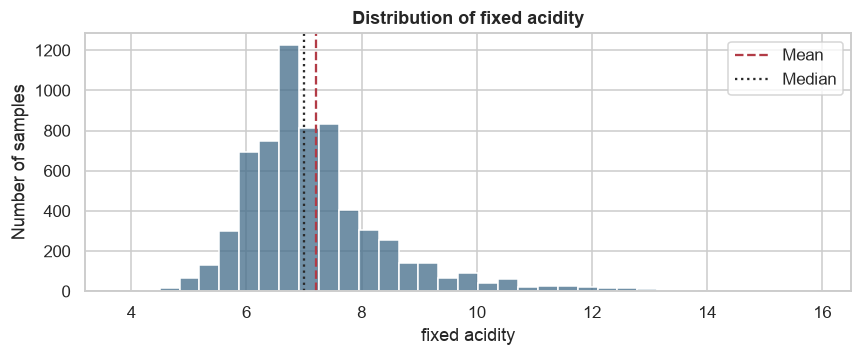

**fixed acidity:** I get a minimum of **3.8**, maximum of **15.9**, mean of **7.215**, and median of **7**. The sample has a longer right tail (skewness 1.72). My pooled IQR check flags **357 samples (5.5%)**. I keep these values for now.

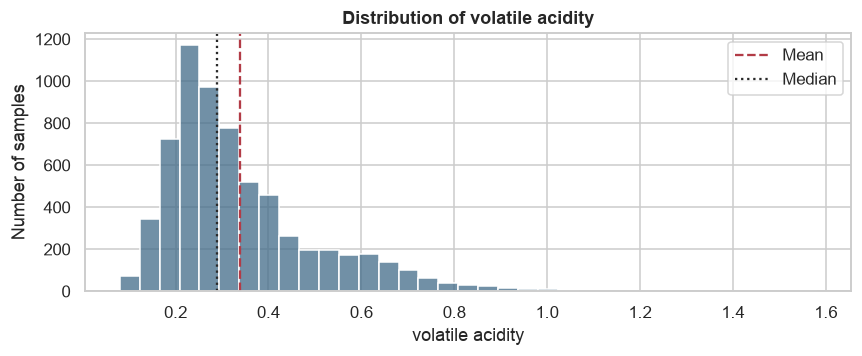

**volatile acidity:** I get a minimum of **0.08**, maximum of **1.58**, mean of **0.3397**, and median of **0.29**. The sample has a longer right tail (skewness 1.50). My pooled IQR check flags **377 samples (5.8%)**. I keep these values for now.

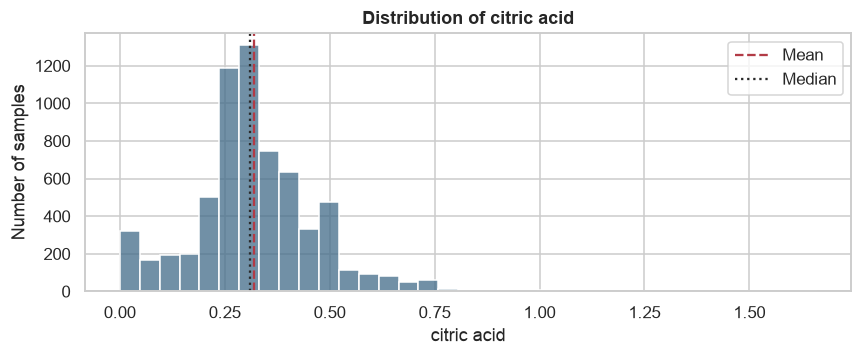

**citric acid:** I get a minimum of **0**, maximum of **1.66**, mean of **0.3186**, and median of **0.31**. The sample has no strong skew by the sample skewness (skewness 0.47). My pooled IQR check flags **509 samples (7.8%)**. I keep these values for now.

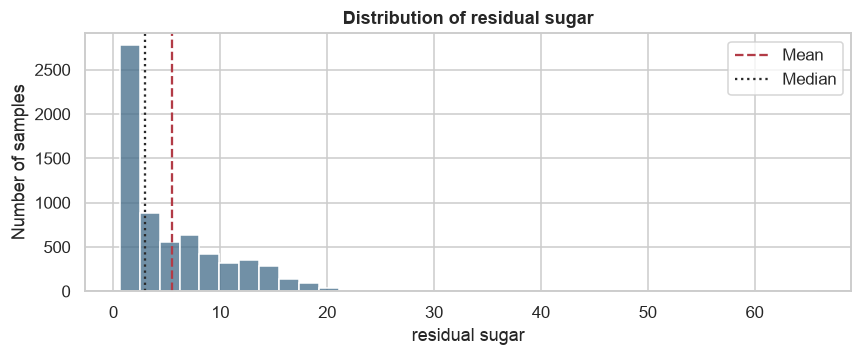

**residual sugar:** I get a minimum of **0.6**, maximum of **65.8**, mean of **5.443**, and median of **3**. The sample has a longer right tail (skewness 1.44). My pooled IQR check flags **118 samples (1.8%)**. I keep these values for now.

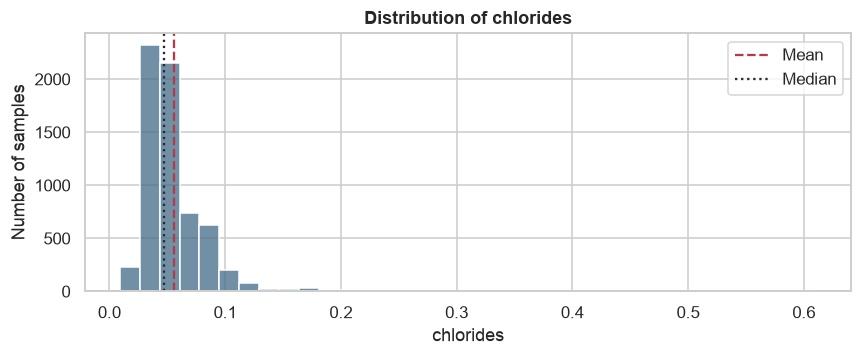

**chlorides:** I get a minimum of **0.009**, maximum of **0.611**, mean of **0.05603**, and median of **0.047**. The sample has a longer right tail (skewness 5.40). My pooled IQR check flags **286 samples (4.4%)**. I keep these values for now.

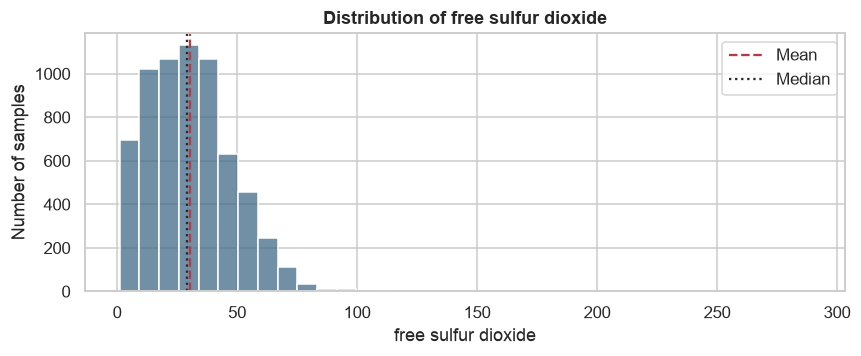

**free sulfur dioxide:** I get a minimum of **1**, maximum of **289**, mean of **30.53**, and median of **29**. The sample has a longer right tail (skewness 1.22). My pooled IQR check flags **62 samples (1.0%)**. I keep these values for now.

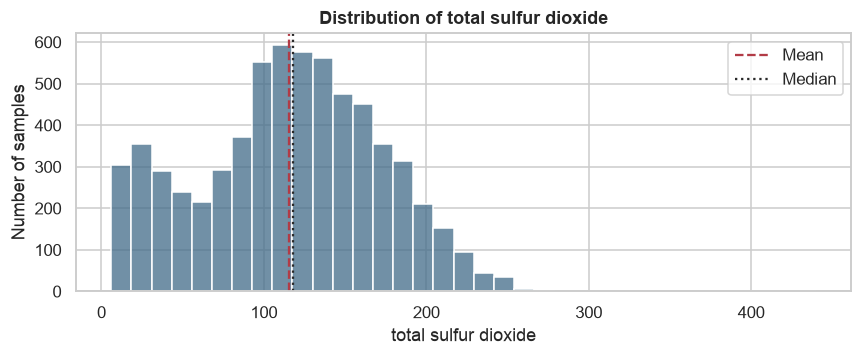

**total sulfur dioxide:** I get a minimum of **6**, maximum of **440**, mean of **115.7**, and median of **118**. The sample has no strong skew by the sample skewness (skewness -0.00). My pooled IQR check flags **10 samples (0.2%)**. I keep these values for now.

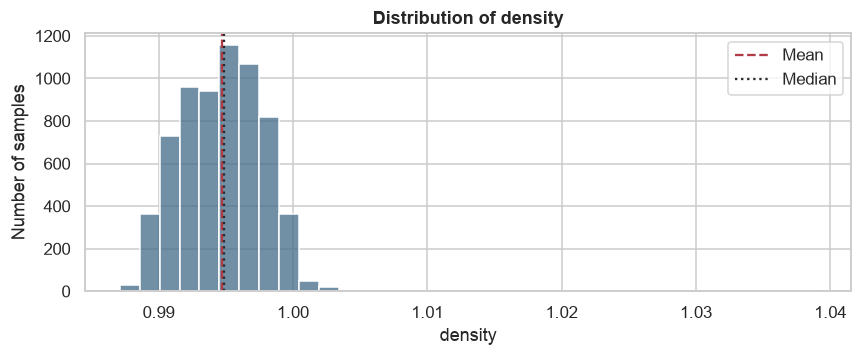

**density:** I get a minimum of **0.9871**, maximum of **1.039**, mean of **0.9947**, and median of **0.9949**. The sample has a longer right tail (skewness 0.50). My pooled IQR check flags **3 samples (0.0%)**. I keep these values for now.

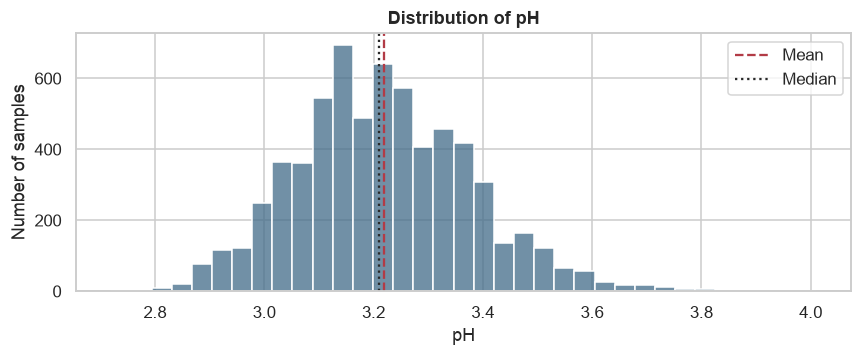

**pH:** I get a minimum of **2.72**, maximum of **4.01**, mean of **3.219**, and median of **3.21**. The sample has no strong skew by the sample skewness (skewness 0.39). My pooled IQR check flags **73 samples (1.1%)**. I keep these values for now.

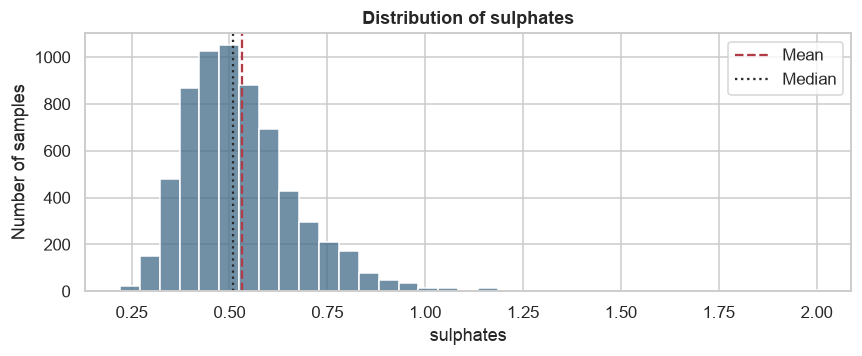

**sulphates:** I get a minimum of **0.22**, maximum of **2**, mean of **0.5313**, and median of **0.51**. The sample has a longer right tail (skewness 1.80). My pooled IQR check flags **191 samples (2.9%)**. I keep these values for now.

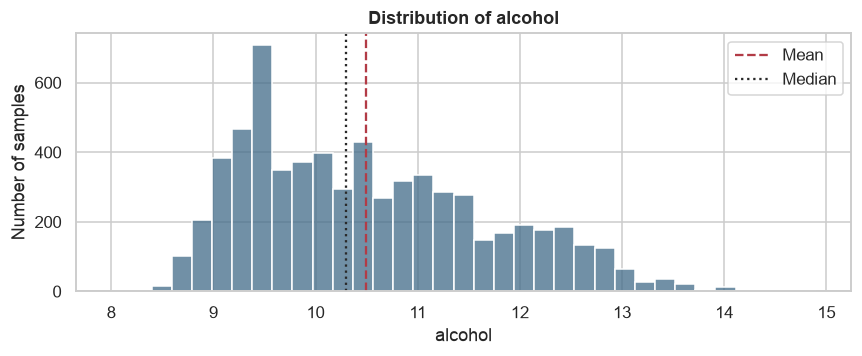

**alcohol:** I get a minimum of **8**, maximum of **14.9**, mean of **10.49**, and median of **10.3**. The sample has a longer right tail (skewness 0.57). My pooled IQR check flags **3 samples (0.0%)**. I keep these values for now.

In [5]:
for col in features:
    fig, ax = plt.subplots(figsize=(8, 3.4))
    sns.histplot(data=wine, x=col, bins=35, color="#426b89", ax=ax)
    ax.axvline(wine[col].mean(), color="#b23b46", linestyle="--", label="Mean")
    ax.axvline(wine[col].median(), color="#292929", linestyle=":", label="Median")
    ax.set(title=f"Distribution of {col}", ylabel="Number of samples")
    ax.legend()
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    r = summary.loc[col]
    skew = wine[col].skew()
    shape = "a longer right tail" if skew > .5 else "a longer left tail" if skew < -.5 else "no strong skew by the sample skewness"
    display(Markdown(f"**{col}:** I get a minimum of **{r['min']:.4g}**, maximum of **{r['max']:.4g}**, mean of **{r['mean']:.4g}**, and median of **{r['median']:.4g}**. The sample has {shape} (skewness {skew:.2f}). My pooled IQR check flags **{int(r['outliers'])} samples ({r['outlier_pct']:.1f}%)**. I keep these values for now."))

### Quality and wine type

I use bar charts for these categories. Wine-type labels get counts and percentages rather than numerical summaries.

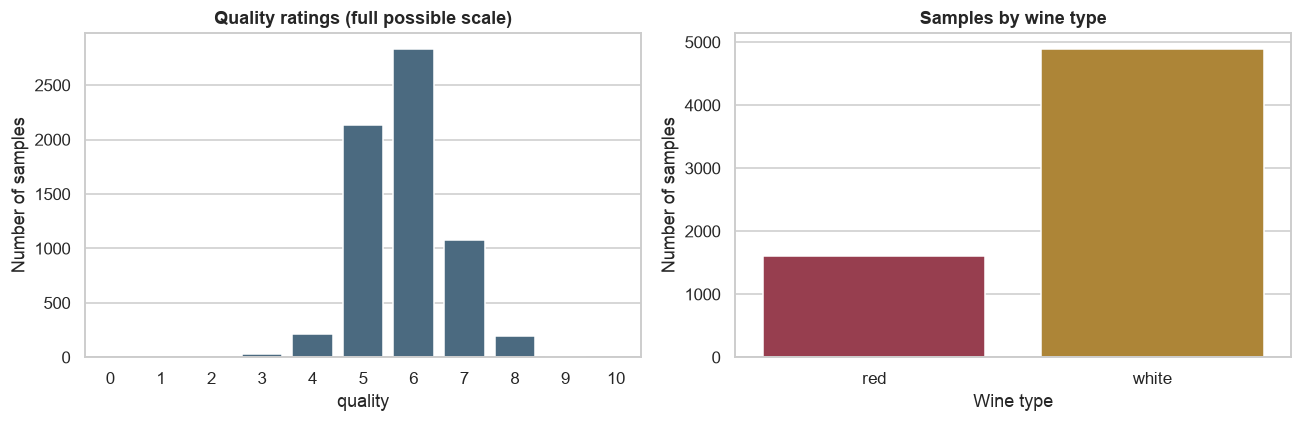

,count,percent
wine_type,,
red,1599,24.61
white,4898,75.39


For **quality**, I get min **3**, max **9**, mean **5.82**, and median **6**. The pooled IQR rule flags **228** ratings, but these are valid scores, not automatic errors. Most ratings cluster around the middle, and the extreme categories have much smaller counts.

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
scores = list(range(11))
sns.countplot(data=wine, x="quality", order=scores, color="#426b89", ax=axes[0])
sns.countplot(data=wine, x="wine_type", order=["red", "white"], hue="wine_type", palette=palette, legend=False, ax=axes[1])
axes[0].set(title="Quality ratings (full possible scale)", ylabel="Number of samples")
axes[1].set(title="Samples by wine type", xlabel="Wine type", ylabel="Number of samples")
fig.tight_layout()
plt.show()
plt.close(fig)
counts = wine.wine_type.value_counts().reindex(["red", "white"])
display(pd.DataFrame({"count": counts, "percent": counts / len(wine) * 100}).round(2))
r = summary.loc["quality"]
display(Markdown(f"For **quality**, I get min **{r['min']:.0f}**, max **{r['max']:.0f}**, mean **{r['mean']:.2f}**, and median **{r['median']:.0f}**. The pooled IQR rule flags **{int(r['outliers'])}** ratings, but these are valid scores, not automatic errors. Most ratings cluster around the middle, and the extreme categories have much smaller counts."))

## 4. Side-by-side box plots

I show the original values, then z-scores so different measurement scales are easier to compare. Wine type is excluded because it's categorical.

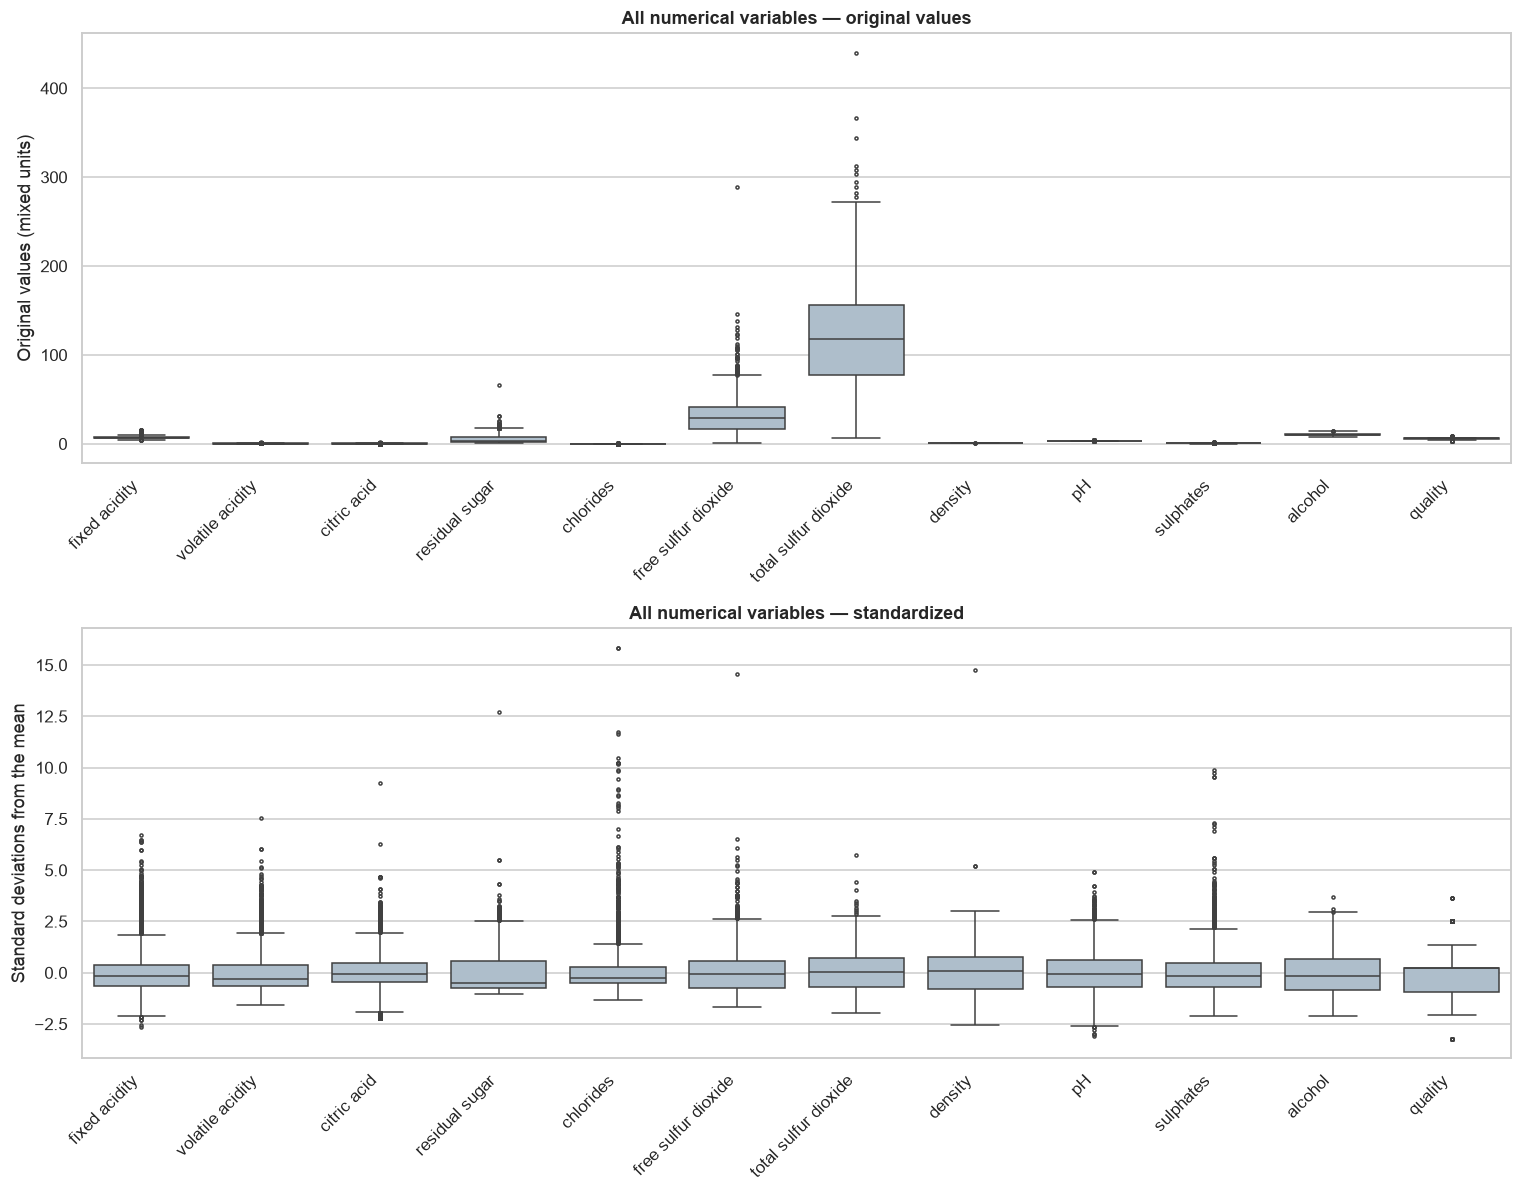

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 11))
sns.boxplot(data=wine[numeric], ax=axes[0], color="#a9bfd0", fliersize=2)
axes[0].set(title="All numerical variables — original values", ylabel="Original values (mixed units)")
z = (wine[numeric] - wine[numeric].mean()) / wine[numeric].std()
sns.boxplot(data=z, ax=axes[1], color="#a9bfd0", fliersize=2)
axes[1].set(title="All numerical variables — standardized", ylabel="Standard deviations from the mean")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    for label in ax.get_xticklabels(): label.set_ha("right")
fig.tight_layout()
plt.show()
plt.close(fig)

I see long tails and outliers more clearly after standardizing. I keep flagged values because they may be valid samples.

## 5. Numerical relationships

I include every numerical column and all samples. I show one triangle to avoid repeating pairs. Quality forms stripes because its scores are discrete.

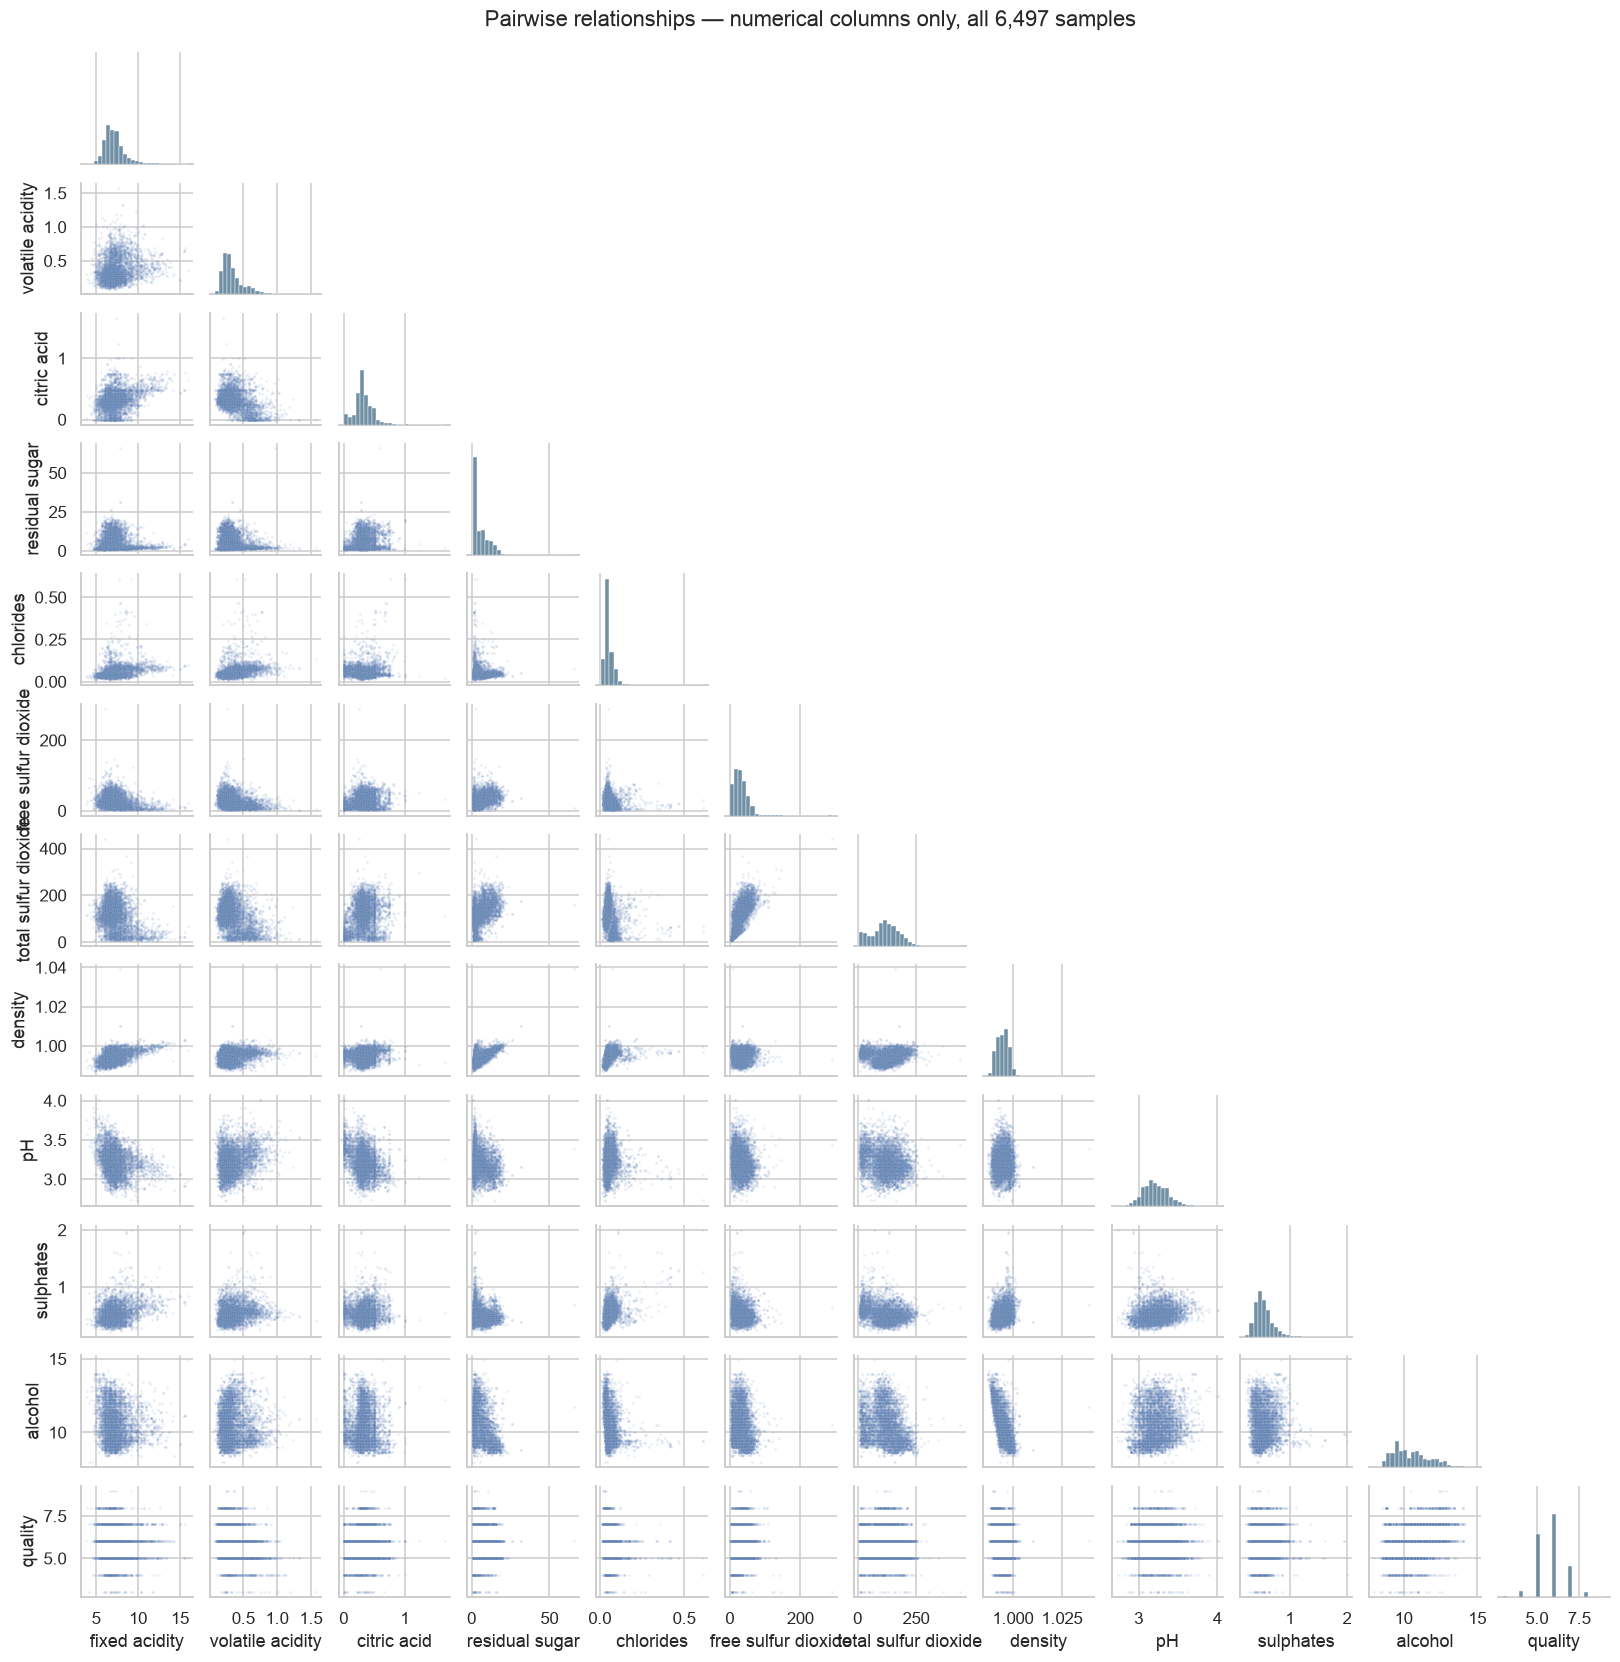

In [8]:
grid = sns.pairplot(wine[numeric], corner=True, diag_kind="hist", height=1.25,
                    plot_kws={"s": 3, "alpha": .12, "rasterized": True},
                    diag_kws={"bins": 25, "color": "#426b89"})
grid.figure.suptitle("Pairwise relationships — numerical columns only, all 6,497 samples", y=1.01)
plt.show()
plt.close(grid.figure)

### Correlations

I use Pearson correlations for linear relationships and Spearman rank correlations for ordered quality ratings. I compare pooled results with each wine type.

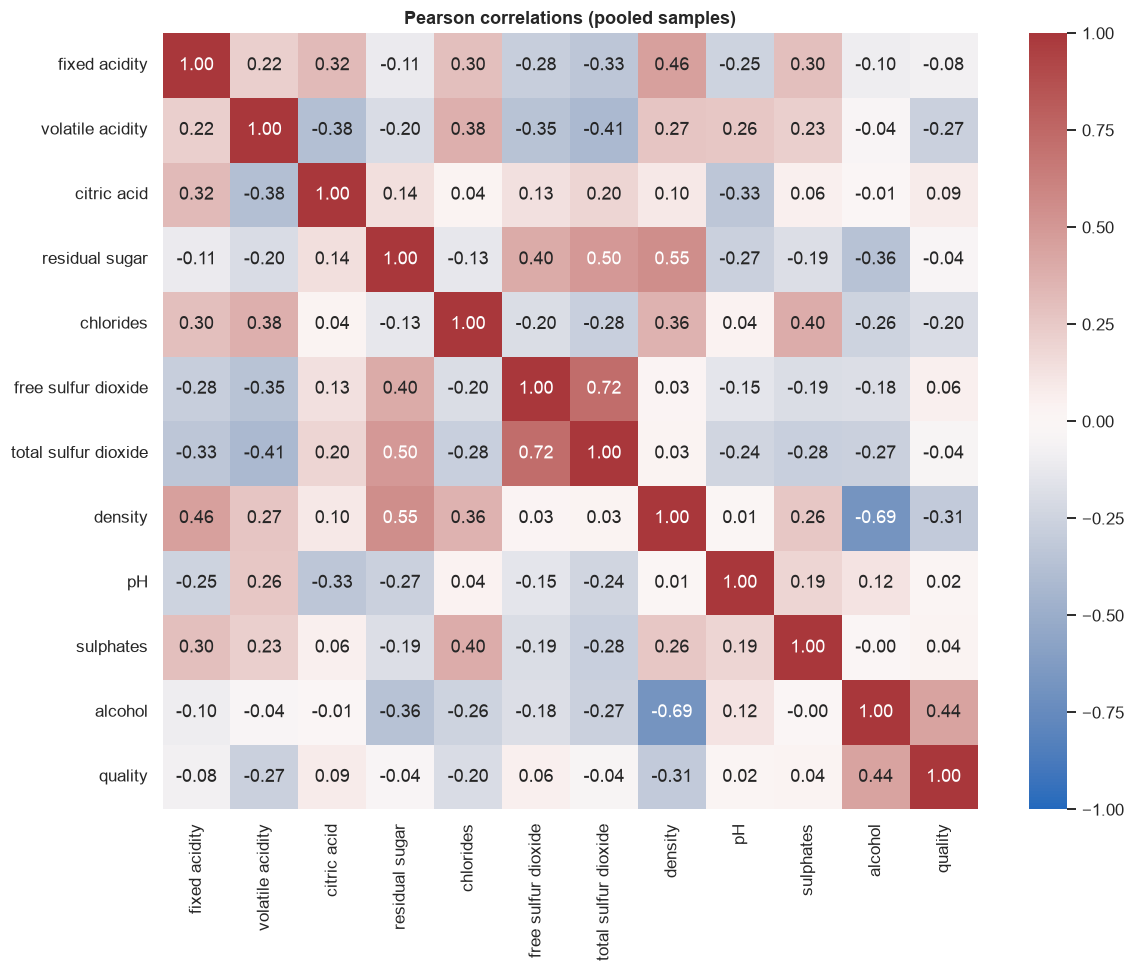

,combined,red,white
fixed acidity,-0.098,0.114,-0.084
volatile acidity,-0.258,-0.381,-0.197
citric acid,0.106,0.213,0.018
residual sugar,-0.017,0.032,-0.082
chlorides,-0.295,-0.190,-0.314
free sulfur dioxide,0.087,-0.057,0.024
total sulfur dioxide,-0.055,-0.197,-0.197
density,-0.323,-0.177,-0.348
pH,0.033,-0.044,0.109
sulphates,0.030,0.377,0.033


For **combined** wines, the strongest positive rank association with quality is **alcohol (0.447)**, and the strongest negative one is **density (-0.323)**. These are associations in this dataset; they don't establish cause and effect.

For **red** wines, the strongest positive rank association with quality is **alcohol (0.479)**, and the strongest negative one is **volatile acidity (-0.381)**. These are associations in this dataset; they don't establish cause and effect.

For **white** wines, the strongest positive rank association with quality is **alcohol (0.440)**, and the strongest negative one is **density (-0.348)**. These are associations in this dataset; they don't establish cause and effect.

In [9]:
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(wine[numeric].corr(), cmap="vlag", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", ax=ax)
ax.set_title("Pearson correlations (pooled samples)")
fig.tight_layout()
plt.show()
plt.close(fig)
quality_corr = pd.DataFrame({"combined": wine[numeric].corr(method="spearman")["quality"].drop("quality"),
    **{t: g[numeric].corr(method="spearman")["quality"].drop("quality") for t, g in wine.groupby("wine_type")}})
display(quality_corr.round(3))
for t in ["combined", "red", "white"]:
    ordered = quality_corr[t].sort_values()
    display(Markdown(f"For **{t}** wines, the strongest positive rank association with quality is **{ordered.index[-1]} ({ordered.iloc[-1]:.3f})**, and the strongest negative one is **{ordered.index[0]} ({ordered.iloc[0]:.3f})**. These are associations in this dataset; they don't establish cause and effect."))

## 6. Wine type versus quality

I show counts and percentages within each wine type. Percentages help me compare the unequal group sizes.

quality,0,1,2,3,4,5,6,7,8,9,10
wine_type,,,,,,,,,,,
red,0,0,0,10,53,681,638,199,18,0,0
white,0,0,0,20,163,1457,2198,880,175,5,0


quality,0,1,2,3,4,5,6,7,8,9,10
wine_type,,,,,,,,,,,
red,0.0,0.0,0.0,0.63,3.31,42.59,39.90,12.45,1.13,0.0,0.0
white,0.0,0.0,0.0,0.41,3.33,29.75,44.88,17.97,3.57,0.1,0.0


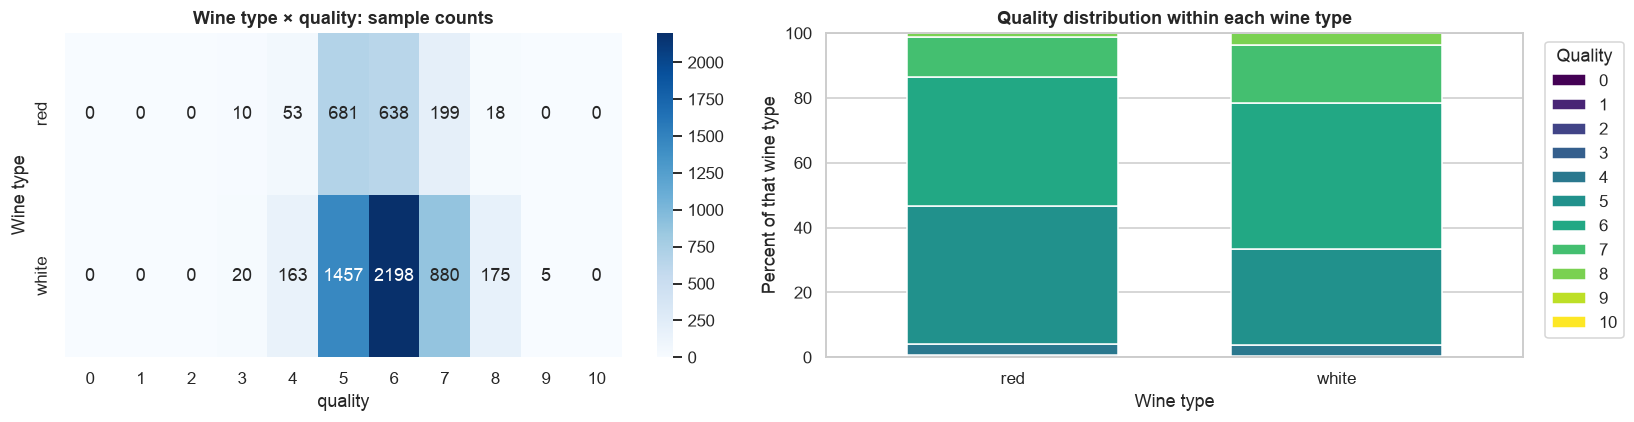

In the **red** file, **13.6%** of samples have a score of 7 or above. I'm using 7 as a descriptive cutoff here, not an official label for wine quality.

In the **white** file, **21.6%** of samples have a score of 7 or above. I'm using 7 as a descriptive cutoff here, not an official label for wine quality.

In [10]:
table = pd.crosstab(wine["wine_type"], wine["quality"]).reindex(index=["red", "white"], columns=scores, fill_value=0)
percent = table.div(table.sum(axis=1), axis=0) * 100
display(table)
display(percent.round(2))
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.heatmap(table, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set(title="Wine type × quality: sample counts", ylabel="Wine type")
percent.plot.bar(stacked=True, colormap="viridis", ax=axes[1], width=.65)
axes[1].set(title="Quality distribution within each wine type", ylabel="Percent of that wine type", xlabel="Wine type", ylim=(0, 100))
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Quality", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()
plt.close(fig)
for t in ["red", "white"]:
    display(Markdown(f"In the **{t}** file, **{percent.loc[t, 7:].sum():.1f}%** of samples have a score of 7 or above. I'm using 7 as a descriptive cutoff here, not an official label for wine quality."))

## 7. Categories, measurements, and color

I compare alcohol by quality and wine type using grouped statistics and box plots. I color scatter plots by wine type or quality to show group patterns.

count    mean  median
wine_type quality                       
red       3           10   9.955   9.925
          4           53  10.265  10.000
          5          681   9.900   9.700
          6          638  10.630  10.500
          7          199  11.466  11.500
          8           18  12.094  12.150
white     3           20  10.345  10.450
          4          163  10.152  10.100
          5         1457   9.809   9.500
          6         2198  10.575  10.500
          7          880  11.368  11.400
          8          175  11.636  12.000
          9            5  12.180  12.500

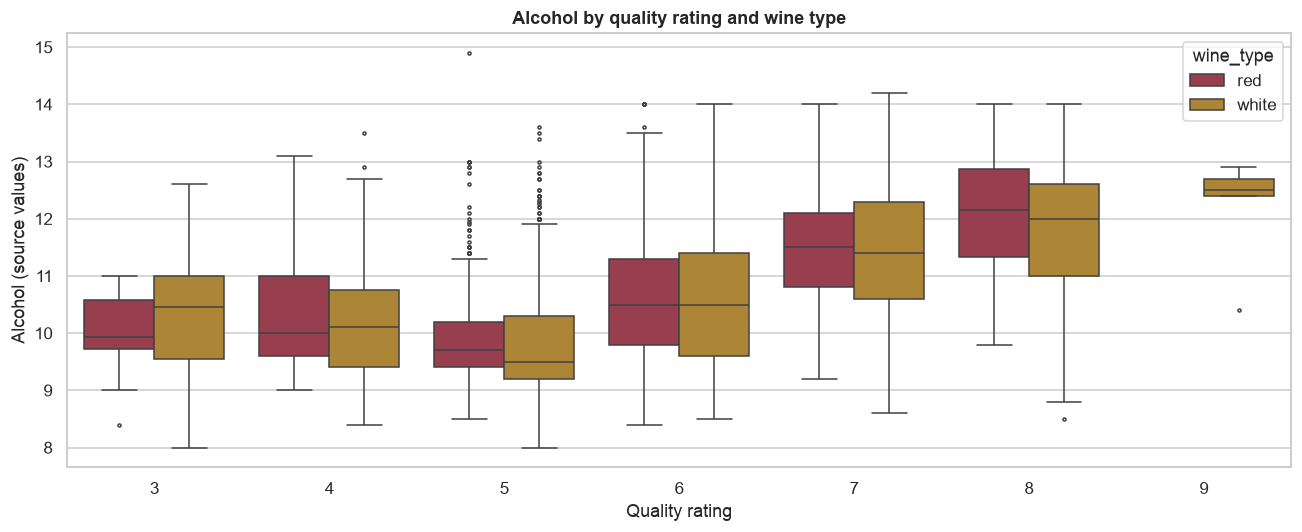

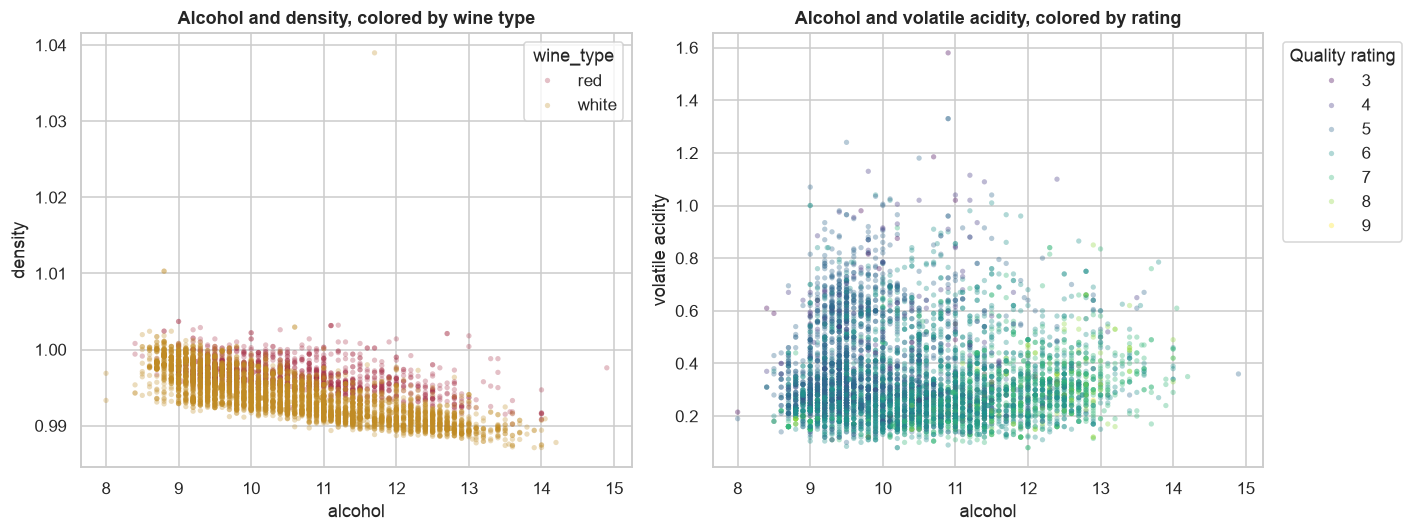

In [11]:
alcohol_groups = wine.groupby(["wine_type", "quality"])["alcohol"].agg(["count", "mean", "median"])
display(alcohol_groups.round(3))
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=wine, x="quality", y="alcohol", hue="wine_type", order=sorted(wine.quality.unique()), palette=palette, fliersize=2, ax=ax)
ax.set(title="Alcohol by quality rating and wine type", xlabel="Quality rating", ylabel="Alcohol (source values)")
fig.tight_layout()
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=wine, x="alcohol", y="density", hue="wine_type", palette=palette, s=12, alpha=.3, linewidth=0, ax=axes[0])
axes[0].set_title("Alcohol and density, colored by wine type")
sns.scatterplot(data=wine, x="alcohol", y="volatile acidity", hue="quality", palette="viridis", s=12, alpha=.35, linewidth=0, ax=axes[1])
axes[1].set_title("Alcohol and volatile acidity, colored by rating")
axes[1].legend(title="Quality rating", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()
plt.close(fig)

I see higher alcohol levels at higher ratings, but the groups overlap. Extreme ratings have few samples, so I read those boxes cautiously.

## 8. Checking repeated rows

I compare quality correlations before and after removing repeated rows to see how much the results change.

In [12]:
deduped = wine.drop_duplicates()
sensitivity = pd.DataFrame({
    "all_rows": wine[numeric].corr(method="spearman")["quality"].drop("quality"),
    "without_repeated_rows": deduped[numeric].corr(method="spearman")["quality"].drop("quality")
})
sensitivity["change"] = sensitivity["without_repeated_rows"] - sensitivity["all_rows"]
display(sensitivity.round(3))
display(Markdown(f"Removing repeated rows leaves **{len(deduped):,} samples**. The largest absolute change in these pooled rank correlations is **{sensitivity['change'].abs().max():.3f}**. I use this as a sensitivity check rather than assuming either version is the true sampling design."))

,all_rows,without_repeated_rows,change
fixed acidity,-0.098,-0.104,-0.006
volatile acidity,-0.258,-0.251,0.006
citric acid,0.106,0.116,0.011
residual sugar,-0.017,-0.028,-0.011
chlorides,-0.295,-0.304,-0.009
free sulfur dioxide,0.087,0.090,0.003
total sulfur dioxide,-0.055,-0.058,-0.003
density,-0.323,-0.349,-0.026
pH,0.033,0.053,0.020
sulphates,0.030,0.036,0.006


Removing repeated rows leaves **5,320 samples**. The largest absolute change in these pooled rank correlations is **0.033**. I use this as a sensitivity check rather than assuming either version is the true sampling design.

## 9. My takeaways

- Most wines have middle-range ratings.
- Alcohol is positively associated with quality, but it doesn't explain ratings alone.
- Red and white wines differ, so I compare them separately as well as together.
- I keep outliers unless I can verify an error.

Limits: These are Portuguese Vinho Verde samples, quality is subjective, and sample IDs and sampling details aren't available. Correlation doesn't prove causation.

